# Monte Carlo: combined productivity + demand shocks (CRS, FIGARO network)

Joint shock: productivity $\eta\sim N(0,\sigma^2 I)$ and a government purchase $g=G\,w$, $w\sim\mathrm{Dirichlet}(\alpha\gamma)$ (prop. = $w=\gamma$). With $p=e^{-L^\top\eta}$ and disposable income $X=1-p'g$:

* **Crowding-out:** $c=X\gamma/p$, so $\ln U=\ln X+\gamma'L^\top\eta$.
* **Redistribution:** $c=X\gamma/p+g$, so $\ln U=\sum_i\gamma_i\ln\!\big[X e^{(L^\top\eta)_i}+g_i/\gamma_i\big]$.
* Output: $s=L'(X\gamma+p\odot g)$, $y=s/p$.

The main object is the **welfare cost of the government purchase given the productivity shock**,
$\Delta=\ln U(\eta,g)-v'\eta$ (what you lose relative to the same shock with no policy). The theory says $\Delta<0$ under redistribution for any $\eta\ne0$ (optimum $g^\star=0$), and $\Delta=\ln X$ under crowding-out.
The simulation estimates how large $\Delta$ is, how it scales with $\sigma$, $G$ and the allocation, and how often the policy would "help" (should be never).



In [ ]:
# ============================================================
#  SETUP
#    Loads FIGARO, builds A_model / gamma / beta, factorizes I-A once.
# ============================================================
from pathlib import Path
import re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csc_matrix, eye, load_npz, save_npz
from scipy.sparse.linalg import splu

FILE_PATH = Path("matrix_eu-ic-io_ind-by-ind_26ed_2024_utf8.csv")
TARGET_INTERMEDIATE_SHARE = 0.99      # rescaling target for the 3 columns with beta <= 0
OUTPUT_DIR = Path("mc_output"); OUTPUT_DIR.mkdir(exist_ok=True)
A_CACHE, META_CACHE = Path("figaro_A_model.npz"), Path("figaro_meta.npz")

def build_model_from_csv():
    df = pd.read_csv(FILE_PATH, index_col="rowLabels", low_memory=False)
    num = df.apply(pd.to_numeric, errors="coerce")
    labs = [l for l in df.index if re.fullmatch(r"[A-Z]{2}_.+", str(l))
            and not str(l).startswith(("W2_", "FIGW1_")) and l in df.columns]
    x = num.loc[labs, :].sum(axis=1)
    active = x[x > 0].index.tolist()
    Z = num.loc[active, active].to_numpy(float)
    xa = x.loc[active].to_numpy(float)
    A = Z / xa[None, :]
    for j in np.where(1.0 - A.sum(axis=0) <= 0)[0]:          # columns with beta <= 0
        A[:, j] *= TARGET_INTERMEDIATE_SHARE / A[:, j].sum()
    p3 = [c for c in num.columns if str(c).endswith("_P3_S14")]
    hc = np.maximum(num.loc[active, p3].sum(axis=1).to_numpy(float), 0.0)
    return csc_matrix(A), hc / hc.sum(), np.array(active, dtype=str)

if A_CACHE.exists() and META_CACHE.exists() and float(np.load(META_CACHE)["target"]) == TARGET_INTERMEDIATE_SHARE:
    A_sparse = load_npz(A_CACHE).tocsc(); meta = np.load(META_CACHE)
    gamma, labels = meta["gamma"], meta["labels"]
    print("Loaded cached model.")
else:
    t0 = time.time(); A_sparse, gamma, labels = build_model_from_csv()
    save_npz(A_CACHE, A_sparse); np.savez(META_CACHE, gamma=gamma, labels=labels, target=TARGET_INTERMEDIATE_SHARE)
    print(f"Built model from CSV in {time.time()-t0:.0f}s and cached it.")

n = A_sparse.shape[0]
beta = 1.0 - np.asarray(A_sparse.sum(axis=0)).ravel()
I = eye(n, format="csc")
LU_M = splu((I - A_sparse).tocsc())          # solves with L' = (I-A)^{-1}
LU_T = splu((I - A_sparse.T).tocsc())        # solves with L^T = (I-A^T)^{-1}
v = LU_M.solve(gamma)                        # Domar weights  v = L' gamma
h = LU_T.solve(np.ones(n))                   # h_i = sum_j L'_{j,i}: output multiplier of final demand in sector i
sumv = v.sum()
country = np.array([l[:2] for l in labels]); countries, cidx = np.unique(country, return_inverse=True)
pos = gamma > 0
print(f"n = {n} sectors, {len(countries)} countries | sum(gamma) = {gamma.sum():.6f} | beta'v = {beta@v:.6f} | sum(v) = {sumv:.4f} | ||v||_2 = {np.linalg.norm(v):.4f}")


COL = dict(co="#D55E00", red="#0072B2", grey="#6B6B6B", green="#009E73", purple="#CC79A7")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200); fig.savefig(OUTPUT_DIR / f"{name}.pdf")
    plt.show()

def to_tex(df, name, float_fmt="{:.4f}", index=False):
    d = df.reset_index() if index else df
    cols = list(d.columns)
    lines = [r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline",
             " & ".join(str(c).replace("_", r"\_") for c in cols) + r" \\ \hline"]
    for _, r in d.iterrows():
        lines.append(" & ".join(float_fmt.format(r[c]) if isinstance(r[c], (float, np.floating))
                                else str(r[c]).replace("_", r"\_") for c in cols) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    (OUTPUT_DIR / f"{name}.tex").write_text("\n".join(lines))
    d.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

def alab(a):  return "prop." if np.isinf(a) else str(int(a))

Built model from CSV in 9s and cached it.
n = 3070 sectors, 49 countries | sum(gamma) = 1.000000 | beta'v = 1.000000 | sum(v) = 1.8695 | ||v||_2 = 0.1569


In [ ]:
# ============================================================
# 1. PARAMETERS
# ============================================================
SEED, R, BATCH = 2026, 1000, 200
SIGMAS = [0.01, 0.025, 0.05, 0.10]
GS     = [0.025, 0.05, 0.10, 0.20]
ALPHAS = [np.inf, 100, 1]                          # allocation of the purchase; inf = proportional to gamma
SIG_F, G_F = 0.05, 0.10                            # single-setting figures
rng = np.random.default_rng(SEED)

def draw_alloc(alpha, B):
    if np.isinf(alpha): return np.tile(gamma[:, None], (1, B))
    W = np.zeros((n, B)); W[pos] = rng.gamma(shape=alpha * gamma[pos][:, None], size=(pos.sum(), B))
    return W / W.sum(0, keepdims=True)

# ============================================================
# 2. MONTE CARLO
#    For each batch of productivity shocks we reuse the same eta across all (G, alpha)
# ============================================================
recs = []; t0 = time.time()
for sigma in SIGMAS:
    left = R
    while left > 0:
        B = min(BATCH, left); left -= B
        eta = sigma * rng.standard_normal((n, B))
        Z = LU_T.solve(eta); P = np.exp(-Z); EZ = np.exp(Z)             # Z = L^T eta, P = prices
        lnU_prod = v @ eta                                              # welfare with no policy
        Y_prod = (v[:, None] * EZ).sum(0)                                # total output with no policy
        for alpha in ALPHAS:
            W = draw_alloc(alpha, B)
            for G in GS:
                X = 1.0 - G * (W * P).sum(0)                             # disposable income
                assert (X > 0).all()
                lnU_co  = np.log(X) + gamma @ Z
                lnU_red = gamma[pos] @ np.log(X * EZ[pos] + G * W[pos] / gamma[pos][:, None])
                S = LU_M.solve(X * gamma[:, None] + G * W * P)           # revenue s = L'(X gamma + p*g)
                Y = (S * EZ).sum(0)                                      # y = s/p, total output
                recs.append(pd.DataFrame(dict(sigma=sigma, G=G, alpha=alab(alpha), lnU_prod=lnU_prod, lnU_co=lnU_co, lnU_red=lnU_red,
                                              X=X, dY_vs_baseline=100 * (Y / sumv - 1), dY_vs_noPolicy=100 * (Y / Y_prod - 1),
                                              pmin=P.min(0), pmax=P.max(0))))
    print(f"sigma={sigma} done ({time.time()-t0:.0f}s)")
D = pd.concat(recs, ignore_index=True)
D["cost_red"] = D.lnU_red - D.lnU_prod        # welfare cost of the purchase, redistribution
D["cost_co"]  = D.lnU_co  - D.lnU_prod        # = ln X, crowding-out
D["U_red"], D["U_co"] = np.exp(D.lnU_red), np.exp(D.lnU_co)

# ============================================================
# 3. STATISTICS
# ============================================================
g_ = D.groupby(["sigma", "G", "alpha"], sort=False)
stats = g_.agg(mean_cost_red=("cost_red", "mean"), q05_cost_red=("cost_red", lambda s: np.quantile(s, .05)), max_cost_red=("cost_red", "max"),
               mean_cost_co=("cost_co", "mean"), mean_U_red=("U_red", "mean"), mean_U_co=("U_co", "mean"),
               std_U_red=("U_red", "std"), mean_dY_vs_noPolicy_pct=("dY_vs_noPolicy", "mean"), mean_X=("X", "mean")).reset_index()
stats["share_draws_policy_helps"] = g_["cost_red"].apply(lambda s: (s > 1e-12).mean()).values
stats["cost_ratio_red_over_co"] = stats.mean_cost_red / stats.mean_cost_co
to_tex(stats, "combined_mc_stats", "{:.5f}")
print(stats.round(5).to_string(index=False))
print("\nDraws in which the purchase improved welfare under redistribution (theory: none):",
      int((D.cost_red > 1e-12).sum()), "of", len(D))
# scaling of the redistribution cost with sigma (proportional basket): slope of log|cost| on log sigma
prop = stats[stats.alpha == "prop."]
for G in GS:
    s = prop[prop.G == G]; slope = np.polyfit(np.log(s.sigma), np.log(-s.mean_cost_red), 1)[0]
    print(f"G={G}: |cost_red| ~ sigma^{slope:.2f} (proportional basket)")

sigma=0.01 done (135s)
sigma=0.025 done (263s)
sigma=0.05 done (391s)
sigma=0.1 done (519s)
 sigma     G alpha  mean_cost_red  q05_cost_red  max_cost_red  mean_cost_co  mean_U_red  mean_U_co  std_U_red  mean_dY_vs_noPolicy_pct  mean_X  share_draws_policy_helps  cost_ratio_red_over_co
 0.010 0.025 prop.       -0.00000      -0.00000      -0.00000      -0.02532     0.99995    0.97495    0.00156                 -0.00020 0.97500                       0.0                 0.00000
 0.010 0.050 prop.       -0.00000      -0.00000      -0.00000      -0.05130     0.99995    0.94995    0.00156                 -0.00039 0.94999                       0.0                 0.00000
 0.010 0.100 prop.       -0.00000      -0.00000      -0.00000      -0.10537     0.99995    0.89994    0.00156                 -0.00078 0.89999                       0.0                 0.00001
 0.010 0.200 prop.       -0.00000      -0.00000      -0.00000      -0.22317     0.99995    0.79994    0.00156                 -0.00156 0

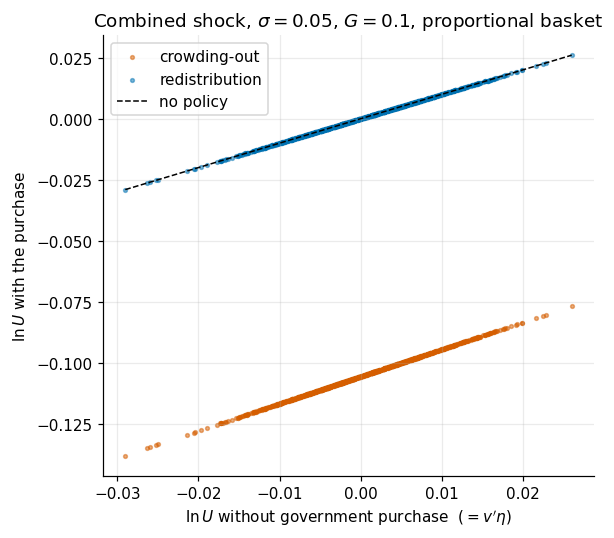

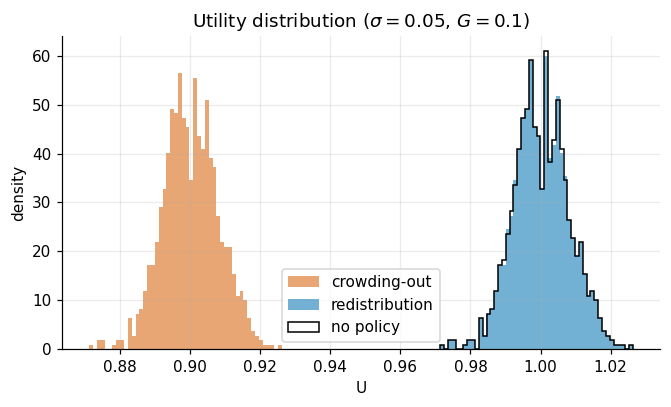

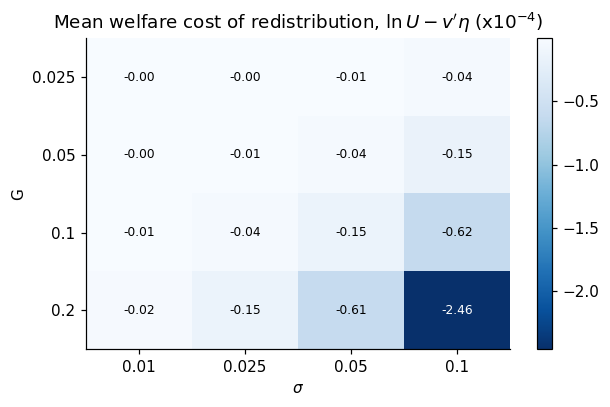

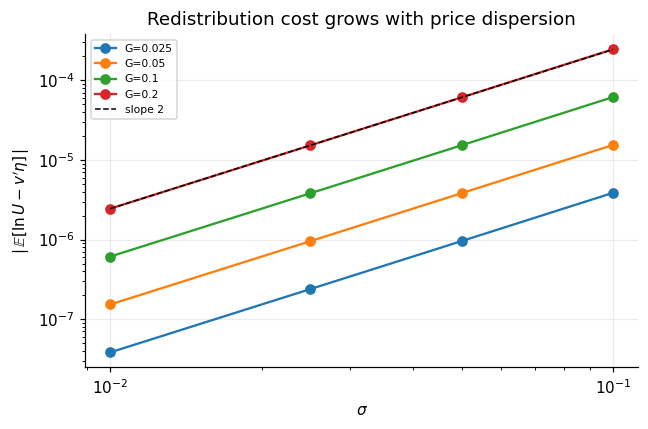

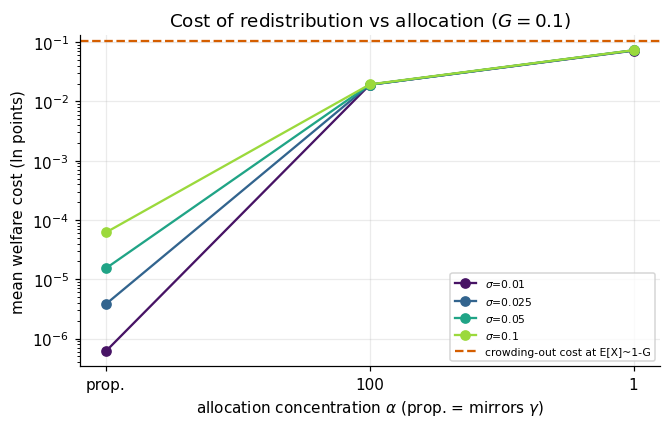

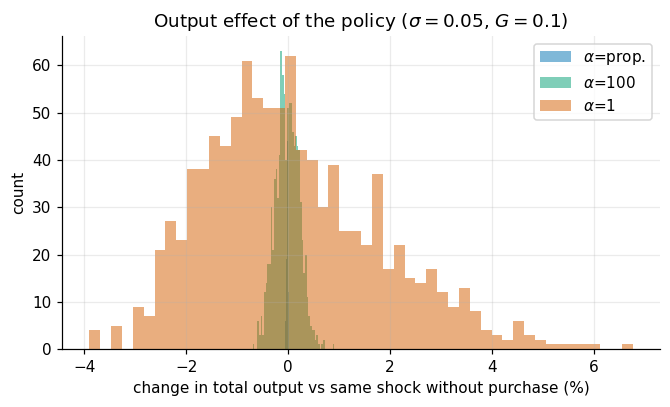


All outputs saved in /content/mc_output


In [ ]:
# ============================================================
# 4. FIGURES
# ============================================================
sel = D[(D.sigma == SIG_F) & (D.G == G_F) & (D.alpha == "prop.")]
# Fig 1 - welfare with the policy vs without: redistribution hugs the 45-degree line, crowding-out is shifted by ln X
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.scatter(sel.lnU_prod, sel.lnU_co, s=6, color=COL["co"], alpha=.5, label="crowding-out")
ax.scatter(sel.lnU_prod, sel.lnU_red, s=6, color=COL["red"], alpha=.5, label="redistribution")
lim = [sel.lnU_prod.min(), sel.lnU_prod.max()]; ax.plot(lim, lim, "k--", lw=1, label="no policy")
ax.set_xlabel(r"$\ln U$ without government purchase  ($=v'\eta$)"); ax.set_ylabel(r"$\ln U$ with the purchase")
ax.set_title(rf"Combined shock, $\sigma={SIG_F}$, $G={G_F}$, proportional basket"); ax.legend(); savefig(fig, "comb_fig1_welfare_scatter")

# Fig 2 - distributions of utility
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.hist(sel.U_co, bins=50, alpha=.55, color=COL["co"], density=True, label="crowding-out")
ax.hist(sel.U_red, bins=50, alpha=.55, color=COL["red"], density=True, label="redistribution")
ax.hist(np.exp(sel.lnU_prod), bins=50, histtype="step", color="k", density=True, label="no policy")
ax.set_xlabel("U"); ax.set_ylabel("density"); ax.set_title(rf"Utility distribution ($\sigma={SIG_F}$, $G={G_F}$)"); ax.legend(); savefig(fig, "comb_fig2_utility_distribution")

# Fig 3 - cost of redistribution: heatmap over (sigma, G), proportional basket
piv = prop.pivot(index="G", columns="sigma", values="mean_cost_red")
fig, ax = plt.subplots(figsize=(5.8, 3.8)); im = ax.imshow(1e4 * piv.values, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns); ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]): ax.text(j, i, f"{1e4*piv.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if piv.values[i, j] < piv.values.min() * .5 else "k")
ax.set_xlabel(r"$\sigma$"); ax.set_ylabel("G"); ax.grid(False); ax.set_title(r"Mean welfare cost of redistribution, $\ln U-v'\eta$ (x$10^{-4}$)")
fig.colorbar(im); savefig(fig, "comb_fig3_cost_heatmap")

# Fig 4 - scaling with sigma (log-log), proportional basket
fig, ax = plt.subplots(figsize=(6, 4))
for G in GS:
    s = prop[prop.G == G]; ax.plot(s.sigma, -s.mean_cost_red, "o-", label=f"G={G}")
sg = np.array(SIGMAS); ref = -prop[prop.G == GS[-1]].mean_cost_red.values[0] * (sg / sg[0]) ** 2
ax.plot(sg, ref, "k--", lw=1, label=r"slope 2"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\sigma$"); ax.set_ylabel(r"$|\,\mathbb{E}[\ln U-v'\eta]\,|$"); ax.set_title("Redistribution cost grows with price dispersion"); ax.legend(fontsize=7)
savefig(fig, "comb_fig4_cost_scaling")

# Fig 5 - effect of the allocation (alpha) on the redistribution cost
fig, ax = plt.subplots(figsize=(6.2, 4)); xi = np.arange(len(ALPHAS))
for sg_, c in zip(SIGMAS, plt.cm.viridis(np.linspace(.05, .85, len(SIGMAS)))):
    ax.plot(xi, [-stats[(stats.sigma == sg_) & (stats.G == G_F) & (stats.alpha == alab(a))].mean_cost_red.values[0] for a in ALPHAS], "o-", color=c, label=rf"$\sigma$={sg_}")
ax.set_yscale("log"); ax.set_xticks(xi); ax.set_xticklabels([alab(a) for a in ALPHAS]); ax.set_xlabel(r"allocation concentration $\alpha$ (prop. = mirrors $\gamma$)")
ax.set_ylabel("mean welfare cost (ln points)"); ax.axhline(-np.log(1 - G_F), color=COL["co"], ls="--", label="crowding-out cost at E[X]~1-G")
ax.set_title(rf"Cost of redistribution vs allocation ($G={G_F}$)"); ax.legend(fontsize=7); savefig(fig, "comb_fig5_cost_vs_allocation")

# Fig 6 - output: policy effect on total output relative to the same shock without policy
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for a, c in zip(["prop.", "100", "1"], [COL["red"], COL["green"], COL["co"]]):
    s = D[(D.sigma == SIG_F) & (D.G == G_F) & (D.alpha == a)]; ax.hist(s.dY_vs_noPolicy, bins=50, alpha=.5, color=c, label=rf"$\alpha$={a}")
ax.set_xlabel("change in total output vs same shock without purchase (%)"); ax.set_ylabel("count")
ax.set_title(rf"Output effect of the policy ($\sigma={SIG_F}$, $G={G_F}$)"); ax.legend(); savefig(fig, "comb_fig6_output_effect")
print("\nAll outputs saved in", OUTPUT_DIR.resolve())